<a href="https://colab.research.google.com/github/adytriaby/PCVK_Ganjil2026/blob/main/Week3_PCVK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Week 3 — Operasi Dasar Pengolahan Citra

**Mata Kuliah:** Pengolahan Citra dan Visi Komputer  
**Materi:** Operasi citra sederhana, operasi aritmatika/logika, denoising, dan image masking.


In [1]:

# CELL 1 — Import library
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
from math import log10, sqrt

print("OpenCV :", cv.__version__)


OpenCV : 5.0.0


## 1. Hubungkan Google Drive

In [13]:

from google.colab import drive
drive.mount('/content/drive')

# Sesuaikan jika folder Images Anda berbeda
IMG_DIR = '/content/drive/MyDrive/PCVK 2026'

print("Folder Images:", IMG_DIR)
print("Folder tersedia:", os.path.exists(IMG_DIR))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder Images: /content/drive/MyDrive/PCVK 2026
Folder tersedia: True


In [16]:

# Helper untuk menampilkan citra
def show_images(images, titles, figsize=(15,5), cmap=None):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        ax = plt.subplot(1, len(images), i+1)
        if len(img.shape) == 2:
            ax.imshow(img, cmap=cmap or 'gray')
        else:
            ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

def read_image(filename, flags=cv.IMREAD_COLOR):
    path = os.path.join(IMG_DIR, filename)
    img = cv.imread(path, flags)
    if img is None:
        raise FileNotFoundError(f"File tidak ditemukan: {path}")
    return img

# Cek file gambar utama
for f in ['peppers.jpg', 'galaxy.jpg', 'couple.tiff', 'crayfish.jpg']:
    p = os.path.join(IMG_DIR, f)
    print(f"{f:15} -> {'ADA' if os.path.exists(p) else 'BELUM ADA'}")


peppers.jpg     -> ADA
galaxy.jpg      -> ADA
couple.tiff     -> ADA
crayfish.jpg    -> ADA


## PRAKTIKUM D1 — Linear Brightness

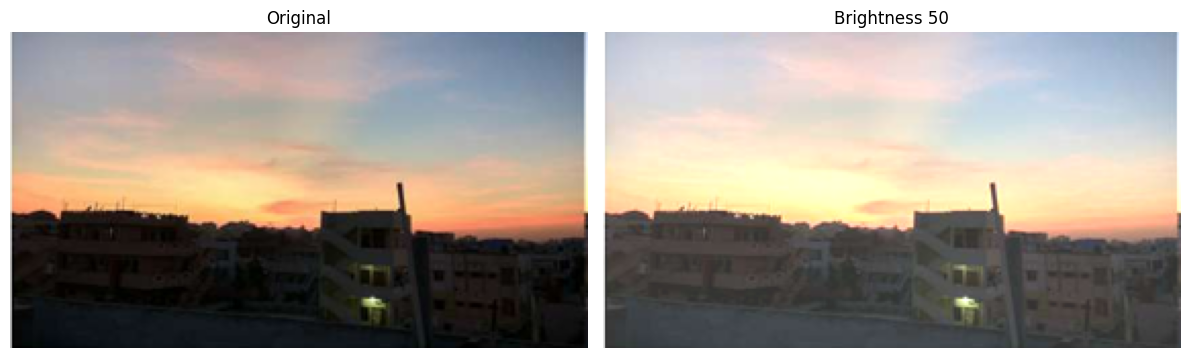

In [18]:

# Rumus modul: g(x,y) = f(x,y) + b
original = read_image('crayfish.jpg')

brightness = 50   # coba juga -50, 20, 80
brightness_img = np.clip(original.astype(np.int16) + brightness, 0, 255).astype(np.uint8)

show_images(
    [original, brightness_img],
    ['Original', f'Brightness {brightness}'],
    figsize=(12,5)
)



## TUGAS 1 — Inverse Citra

Rumus modul:

`g(x,y) = 255 - f(x,y)`

Hasilnya merupakan citra negatif.


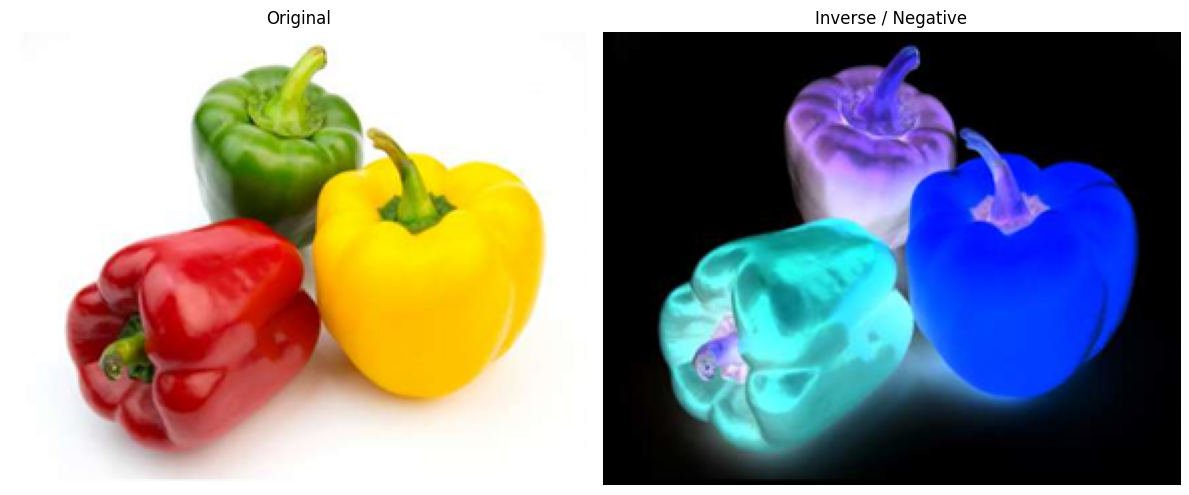

In [19]:

original = read_image('peppers.jpg')
inverse = 255 - original

show_images(
    [original, inverse],
    ['Original', 'Inverse / Negative'],
    figsize=(12,5)
)


## TUGAS 2 — Transformasi Contrast

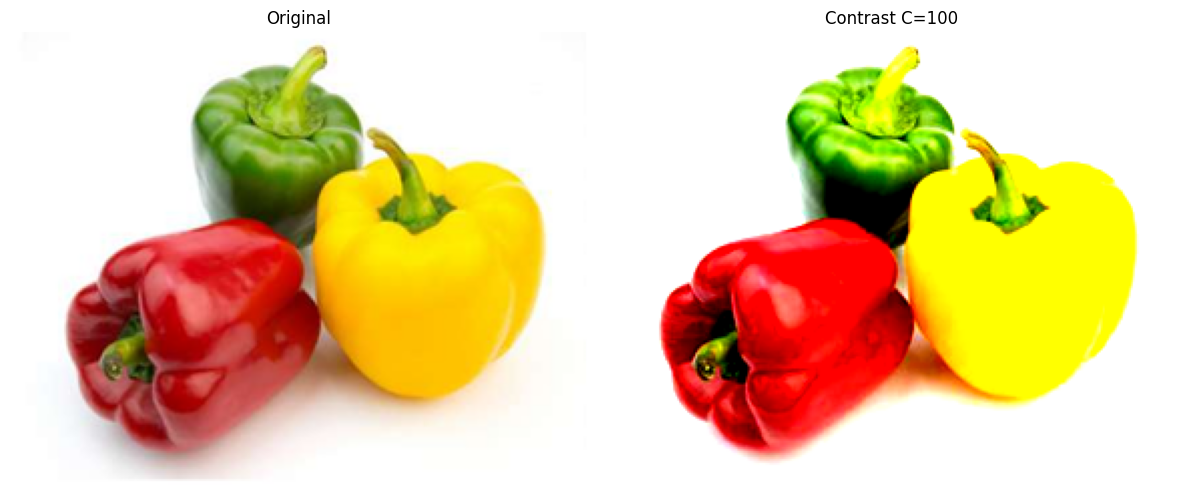

In [20]:

# Rumus factor pada modul:
# F = 259(C + 255) / [255(259 - C)]
# R' = F(R - 128) + 128, berlaku untuk R, G, B

def contrast_transform(img, C):
    if C >= 259 or C <= -259:
        raise ValueError("Gunakan nilai contrast antara -258 dan 258.")
    factor = (259 * (C + 255)) / (255 * (259 - C))
    result = factor * (img.astype(np.float32) - 128) + 128
    return np.clip(result, 0, 255).astype(np.uint8)

original = read_image('peppers.jpg')

C = 100
contrast_img = contrast_transform(original, C)

show_images(
    [original, contrast_img],
    ['Original', f'Contrast C={C}'],
    figsize=(12,5)
)


## TUGAS 3 — Logarithmic Brightness

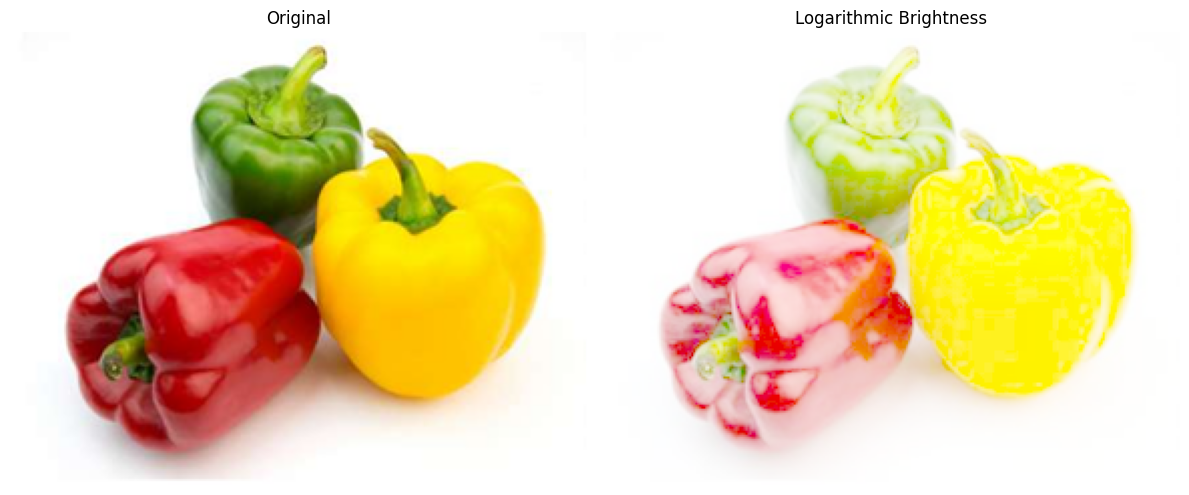

In [21]:

# Rumus modul: s = c * log(1 + r)

def log_brightness(img):
    img_float = img.astype(np.float32)
    c = 255 / np.log1p(255)
    result = c * np.log1p(img_float)
    return np.clip(result, 0, 255).astype(np.uint8)

original = read_image('peppers.jpg')
log_img = log_brightness(original)

show_images(
    [original, log_img],
    ['Original', 'Logarithmic Brightness'],
    figsize=(12,5)
)


## TUGAS 4 — Grayscale: Averaging, Lightness, Luminance

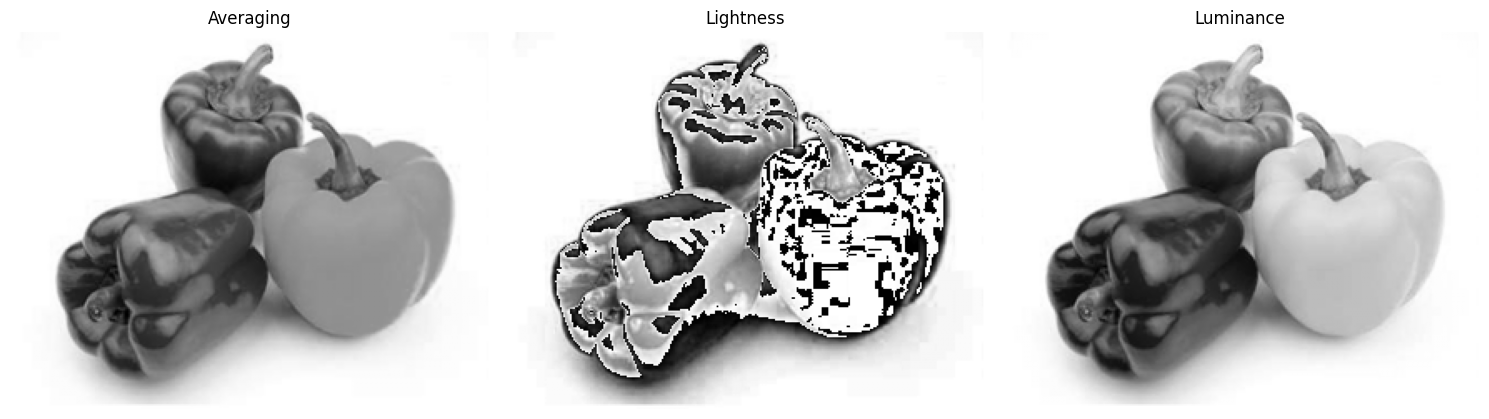

In [22]:

original = read_image('peppers.jpg')
b, g, r = cv.split(original)

# Karena OpenCV membaca BGR, formula ditulis dengan channel RGB:
# Averaging = (R + G + B) / 3
gray_averaging = ((r.astype(np.float32) + g + b) / 3).astype(np.uint8)

# Lightness = (max(R,G,B) + min(R,G,B)) / 2
gray_lightness = ((np.maximum.reduce([r,g,b]) + np.minimum.reduce([r,g,b])) / 2).astype(np.uint8)

# Luminance = 0.21R + 0.72G + 0.07B
gray_luminance = (0.21*r + 0.72*g + 0.07*b).astype(np.uint8)

show_images(
    [gray_averaging, gray_lightness, gray_luminance],
    ['Averaging', 'Lightness', 'Luminance'],
    figsize=(15,5),
    cmap='gray'
)


## TUGAS 5 — Pertahankan Warna Merah, Bagian Lain Grayscale

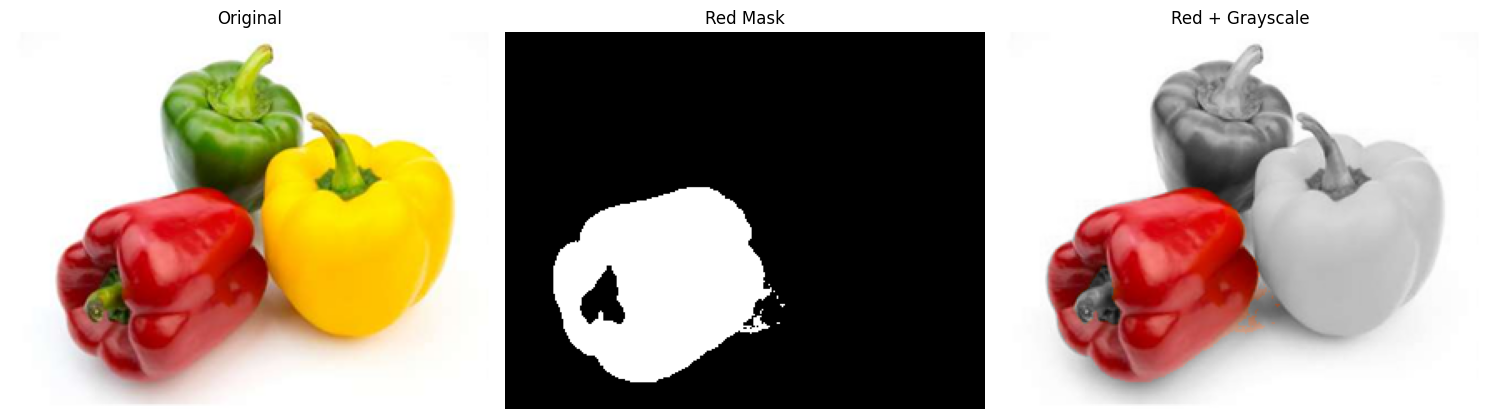

In [23]:

original = read_image('peppers.jpg')

# Konversi BGR -> HSV agar pemilihan warna lebih stabil
hsv = cv.cvtColor(original, cv.COLOR_BGR2HSV)

# Rentang merah pada HSV OpenCV berada di sekitar 0 dan 179
lower_red1 = np.array([0, 80, 50])
upper_red1 = np.array([10, 255, 255])
lower_red2 = np.array([170, 80, 50])
upper_red2 = np.array([179, 255, 255])

mask1 = cv.inRange(hsv, lower_red1, upper_red1)
mask2 = cv.inRange(hsv, lower_red2, upper_red2)
red_mask = cv.bitwise_or(mask1, mask2)

gray = cv.cvtColor(original, cv.COLOR_BGR2GRAY)
gray_bgr = cv.cvtColor(gray, cv.COLOR_GRAY2BGR)

result = np.where(red_mask[..., None] > 0, original, gray_bgr)

show_images(
    [original, red_mask, result],
    ['Original', 'Red Mask', 'Red + Grayscale'],
    figsize=(15,5)
)


## TUGAS 6 — Gamma Correction

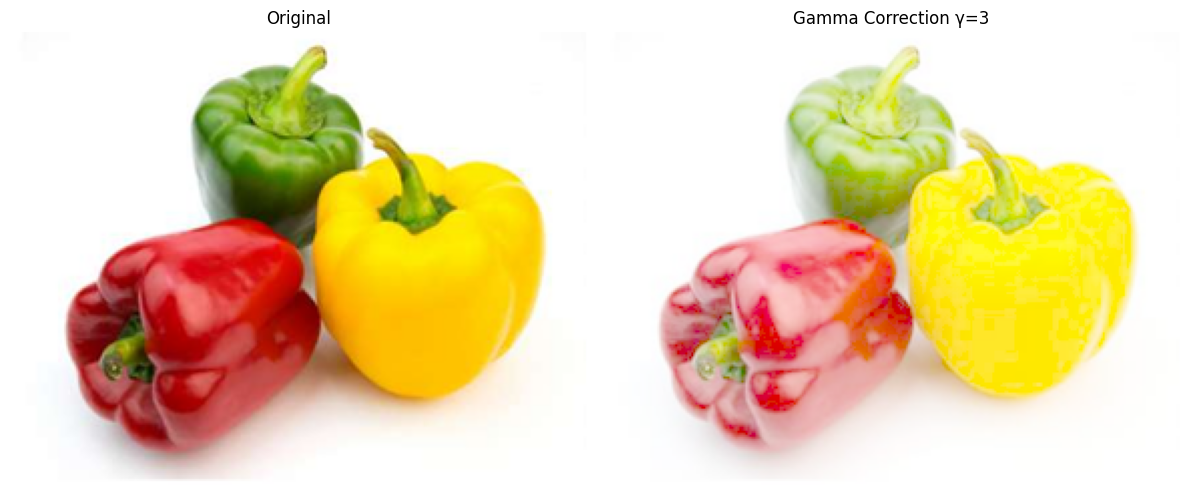

In [24]:

# Rumus modul:
# I' = 255 * (I / 255)^(1/gamma)

def gamma_correction(img, gamma):
    if gamma <= 0:
        raise ValueError("Gamma harus > 0")
    table = np.array([
        255 * ((i / 255.0) ** (1.0 / gamma))
        for i in np.arange(256)
    ]).astype("uint8")
    return cv.LUT(img, table)

original = read_image('peppers.jpg')

gamma = 3
gamma_img = gamma_correction(original, gamma)

show_images(
    [original, gamma_img],
    ['Original', f'Gamma Correction γ={gamma}'],
    figsize=(12,5)
)


## TUGAS 7 — Simulasi Image Depth

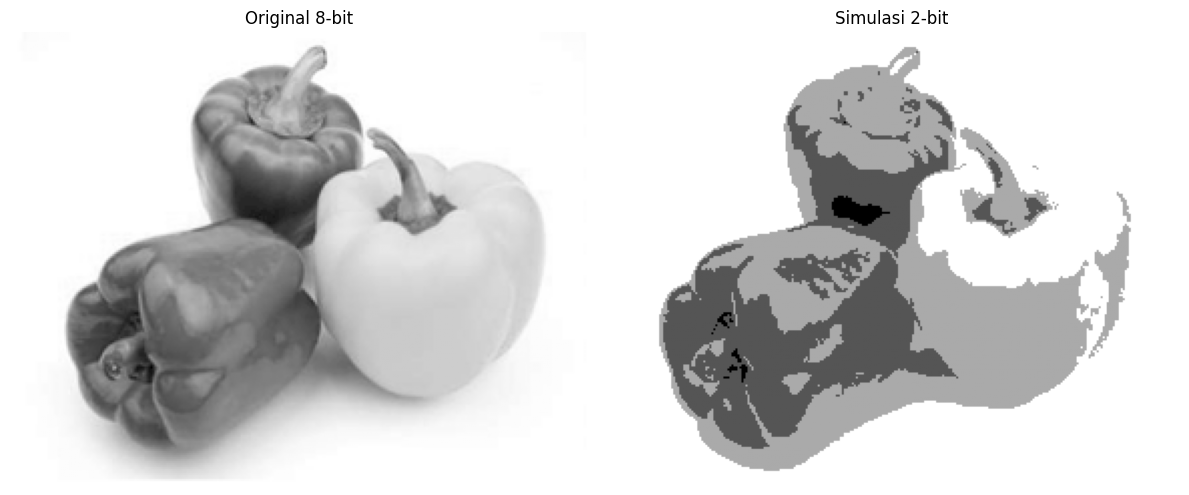

In [25]:

original = read_image('peppers.jpg', cv.IMREAD_GRAYSCALE)

def image_depth(img, bit_depth):
    if bit_depth < 1 or bit_depth > 8:
        raise ValueError("bit_depth harus 1 sampai 8")
    levels = 2**bit_depth
    level = 255 / (levels - 1)
    depth_image = np.round(img / level) * level
    return np.clip(depth_image, 0, 255).astype(np.uint8)

bit_depth = 2
depth_img = image_depth(original, bit_depth)

show_images(
    [original, depth_img],
    ['Original 8-bit', f'Simulasi {bit_depth}-bit'],
    figsize=(12,5),
    cmap='gray'
)



## TUGAS 8 — Average Denoising + PSNR

Modul meminta percobaan dengan 10, 20, 40, 80, dan 100 citra Gaussian Noise. Nilai PSNR kemudian dicatat dan dibandingkan.


In [26]:

# Membaca citra asli dan semua noise
original = cv.imread(os.path.join(IMG_DIR, 'galaxy.jpg'))

noise_files = sorted(glob.glob(os.path.join(IMG_DIR, 'noises', '*.jpg')))
print("Jumlah file noise:", len(noise_files))

cv_img = [cv.imread(f) for f in noise_files]

def PSNR(img1, img2):
    img1 = img1.astype(np.float32)
    img2 = img2.astype(np.float32)
    mse = np.mean((img1 - img2) ** 2)
    if mse == 0:
        return 100
    return 20 * log10(255.0 / sqrt(mse))

def average_denoising(images, n):
    selected = images[:n]
    stack = np.stack(selected).astype(np.float32)
    return np.mean(stack, axis=0).astype(np.uint8)

results = []

for n in [10, 20, 40, 80, 100]:
    if len(cv_img) < n:
        print(f"Data hanya memiliki {len(cv_img)} citra noise, sehingga {n} tidak bisa dihitung.")
        continue

    denoised = average_denoising(cv_img, n)
    psnr_value = PSNR(original, denoised)
    results.append((n, psnr_value))

    show_images(
        [original, denoised],
        ['Original', f'Average {n} citra — PSNR {psnr_value:.2f} dB'],
        figsize=(12,5)
    )

print("\nTabel PSNR")
print("-"*35)
print(f"{'Jumlah Citra':<18}{'PSNR (dB)':>12}")
for n, p in results:
    print(f"{n:<18}{p:>12.2f}")


Jumlah file noise: 0
Data hanya memiliki 0 citra noise, sehingga 10 tidak bisa dihitung.
Data hanya memiliki 0 citra noise, sehingga 20 tidak bisa dihitung.
Data hanya memiliki 0 citra noise, sehingga 40 tidak bisa dihitung.
Data hanya memiliki 0 citra noise, sehingga 80 tidak bisa dihitung.
Data hanya memiliki 0 citra noise, sehingga 100 tidak bisa dihitung.

Tabel PSNR
-----------------------------------
Jumlah Citra         PSNR (dB)



### Analisis Tugas 8

Isi kesimpulan berdasarkan angka PSNR yang muncul setelah notebook dijalankan.

- Apakah peningkatan jumlah citra selalu memberikan peningkatan PSNR yang signifikan?
- Pada jumlah citra berapa peningkatan mulai tidak terlalu signifikan?
- Apa kesimpulan dari percobaan?

Secara teori dari modul, semakin banyak citra yang dirata-ratakan, hasil denoising cenderung semakin baik dan PSNR meningkat; tetapi besar peningkatannya perlu dilihat dari hasil eksperimen Anda.


## TUGAS 9 — Image Masking dan Operator Logika

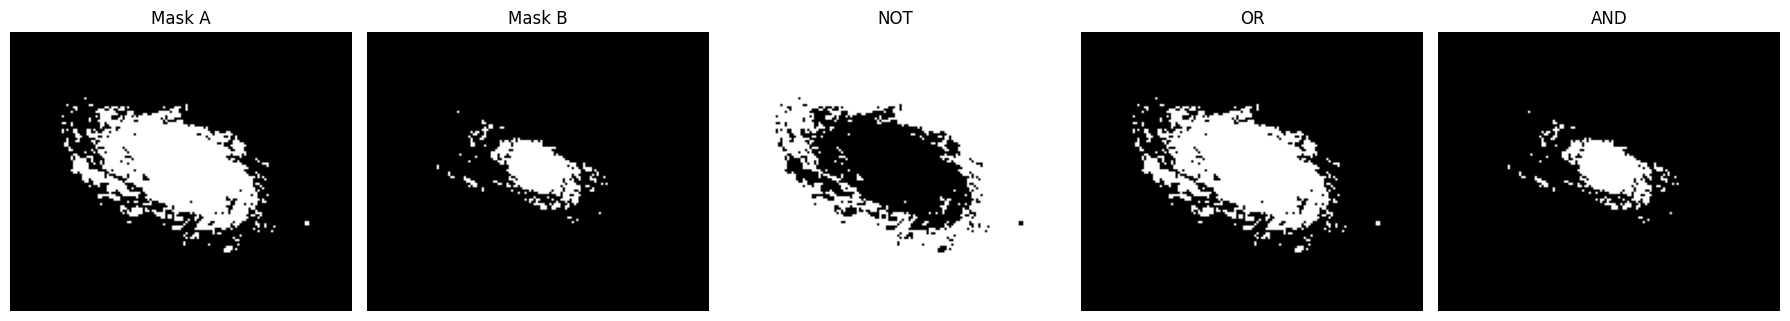

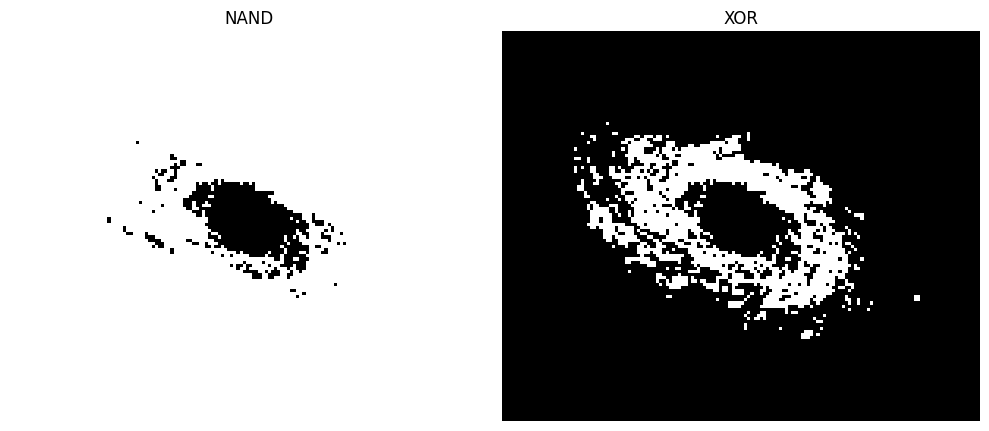

In [27]:

# Untuk demonstrasi operasi logika, gunakan dua citra/mask biner dengan ukuran sama.
# Citra couple.tiff digunakan sebagai input utama.
couple = read_image('couple.tiff')

# Buat mask berdasarkan grayscale dan threshold otomatis
gray_couple = cv.cvtColor(couple, cv.COLOR_BGR2GRAY)
_, mask_a = cv.threshold(gray_couple, 127, 255, cv.THRESH_BINARY)

# Mask kedua dibuat dari threshold yang berbeda agar operasi logika terlihat.
_, mask_b = cv.threshold(gray_couple, 190, 255, cv.THRESH_BINARY)

not_img = cv.bitwise_not(mask_a)
or_img = cv.bitwise_or(mask_a, mask_b)
and_img = cv.bitwise_and(mask_a, mask_b)
nand_img = cv.bitwise_not(and_img)
xor_img = cv.bitwise_xor(mask_a, mask_b)

show_images(
    [mask_a, mask_b, not_img, or_img, and_img],
    ['Mask A', 'Mask B', 'NOT', 'OR', 'AND'],
    figsize=(18,4),
    cmap='gray'
)

show_images(
    [nand_img, xor_img],
    ['NAND', 'XOR'],
    figsize=(10,5),
    cmap='gray'
)



### Analisis Tugas 9

- **NOT:** membalik foreground menjadi background dan sebaliknya.
- **OR:** pixel menjadi foreground jika salah satu mask memiliki foreground.
- **AND:** pixel menjadi foreground jika kedua mask sama-sama foreground.
- **NAND:** kebalikan dari AND.
- **XOR:** foreground ketika kedua mask berbeda.

Pada percobaan ini, bentuk output juga dipengaruhi oleh cara `mask_a` dan `mask_b` dibuat melalui threshold.


## TUGAS 10 — Foto Malam Hari

Saving malam.png to malam.png


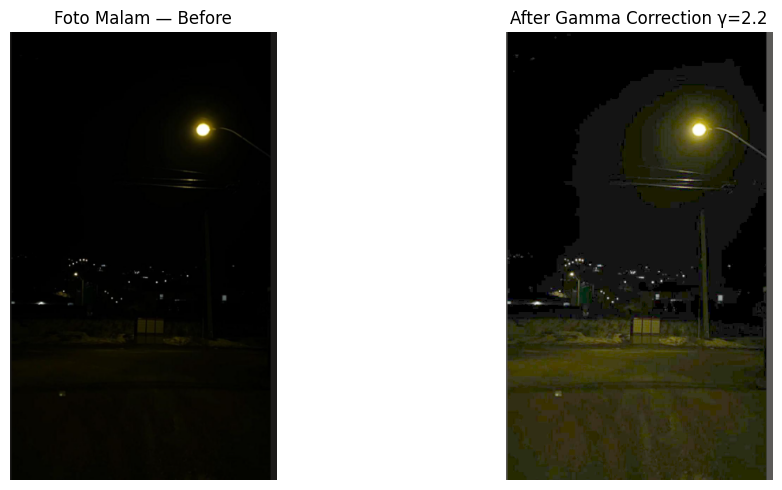

In [28]:

# Upload foto malam hari secara langsung ke Colab
from google.colab import files

uploaded = files.upload()
night_name = next(iter(uploaded.keys()))

night = cv.imread(night_name)
if night is None:
    raise ValueError("Foto gagal dibaca.")

# Pilihan metode: Gamma Correction
gamma = 2.2
night_result = gamma_correction(night, gamma)

show_images(
    [night, night_result],
    ['Foto Malam — Before', f'After Gamma Correction γ={gamma}'],
    figsize=(12,5)
)



### Analisis Tugas 10

**Metode:** Gamma Correction.

**Alasan:** gamma correction dapat mengubah pemetaan intensitas sehingga detail pada area gelap dapat dibuat lebih terlihat tanpa sekadar menambahkan nilai brightness secara langsung.

**Parameter:** mulai dari `gamma = 1.5`, `2.0`, `2.2`, atau `3.0`, lalu bandingkan hasil visual.

**Risiko:** jika koreksi terlalu kuat, area terang dapat menjadi terlalu terang dan detail/highlight dapat hilang. Karena itu parameter perlu disesuaikan dengan kondisi foto.


## TUGAS 11 — Perbaikan Kualitas `crayfish.jpg`

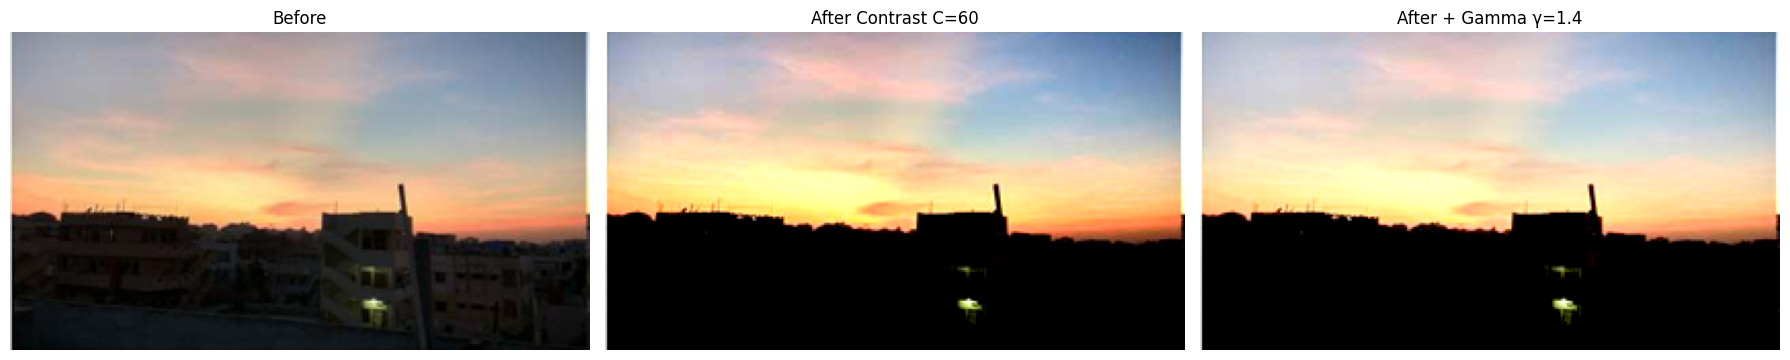

In [29]:

crayfish = read_image('crayfish.jpg')

# Kombinasi sederhana:
# 1) Contrast meningkatkan penyebaran intensitas.
# 2) Gamma membantu mengatur pemetaan intensitas.
# 3) Gaussian blur ringan dapat mengurangi noise kecil (opsional).

contrast_value = 60
gamma_value = 1.4

step1 = contrast_transform(crayfish, contrast_value)
step2 = gamma_correction(step1, gamma_value)

show_images(
    [crayfish, step1, step2],
    ['Before', f'After Contrast C={contrast_value}', f'After + Gamma γ={gamma_value}'],
    figsize=(18,5)
)



### Analisis Tugas 11

**Metode yang dipilih:** Contrast + Gamma Correction.

**Alasan pemilihan:** kedua operasi bekerja pada pemetaan intensitas. Contrast digunakan untuk memperlebar penyebaran intensitas, sedangkan gamma digunakan untuk mengatur tingkat terang/gelap.

**Menentukan parameter terbaik:** coba beberapa kombinasi, misalnya:
- Contrast: `20`, `40`, `60`, `80`
- Gamma: `1.2`, `1.4`, `1.6`, `2.0`

Pilih parameter berdasarkan hasil visual yang mempertahankan detail objek dan tidak membuat area terang terlalu berlebihan.

**Before-after:** hasil sudah ditampilkan pada cell sebelumnya.



# Kesimpulan Praktikum

Pada praktikum ini telah diimplementasikan operasi dasar pengolahan citra menggunakan Google Colab, yaitu:

1. Linear brightness
2. Inverse / negative image
3. Contrast
4. Logarithmic brightness
5. Grayscale averaging, lightness, dan luminance
6. Pemilihan warna tertentu dan grayscale
7. Gamma correction
8. Simulasi image depth
9. Average denoising dan pengukuran PSNR
10. Image masking dengan NOT, OR, AND, NAND, XOR
11. Peningkatan foto malam hari
12. Perbaikan kualitas `crayfish.jpg`

**Catatan pengumpulan:** setelah semua cell dijalankan, simpan notebook sebagai `Week3.ipynb` dan simpan salinannya ke repository GitHub sesuai instruksi modul.
